# Shape optimization beyond matching a stress–strain curve

This notebook actually optimizes **two different objectives** on the same 3×3 finite-hinge grid. Each design starts from the same two small vertex offsets, uses the same elastic coefficients and seven compression steps, and must satisfy the same geometric restrictions.

| Objective | Quantity being designed | Cost minimized |
|---|---|---|
| Target secant stiffness | Final nominal stress divided by the final strain | Squared relative error from one stiffness target |
| Uniform support forces | Three vertical reactions on the bottom grip | Squared coefficient of variation |

The stiffness target is a **single scalar at 4% compression**, rather than an entire curve or a tangent stiffness. Uniformity additionally needs a nonzero-load restriction: equal zero forces would otherwise be an unhelpful solution.

Run the cells in order after installing `pip install -e ".[notebook]"` from the repository root. The executable equivalent is `python examples/optimize_objectives.py --objective all --output outputs`.

In [1]:
from pathlib import Path
import sys

import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

# Set precision BEFORE constructing the geometry and its numerical arrays.
jax.config.update("jax_enable_x64", True)
%matplotlib inline

# Locate the companion example from either the repository or examples directory.
example_dir = next(
    path
    for path in (Path.cwd(), Path.cwd() / "examples")
    if (path / "optimize_square_grid.py").exists()
)
if str(example_dir) not in sys.path:
    sys.path.insert(0, str(example_dir))

# This module has no import-time simulation; build_problem() explicitly sets it up.
from optimize_square_grid import build_problem  # noqa: E402 — after example-path setup
from rotating_polygons import minimize_design, reaction_forces  # noqa: E402 — after example-path setup
from rotating_polygons.plotting import plot_geometry  # noqa: E402 — after example-path setup

print("JAX", jax.__version__, "on", jax.default_backend())

JAX 0.8.0 on cpu


## Reuse the model, then expose the measurements

`build_problem()` constructs the geometry, clamped top/bottom boundary conditions, shape map, initialization, potential, and BFGS equilibrium solver used in notebook 01. It does **not** run the outer design optimization. Its two shape variables move the upper vertex horizontally and the right vertex vertically, repeating these offsets on all nine polygons. The bounds are ±0.12 length units.

The inner equilibrium tolerance is `1e-9` on the free-force residual norm, with at most 500 BFGS iterations per strain. The continuation steps are `0, …, 0.04`; earlier equilibria initialize later ones. Here the objective uses only the final response, but the path still matters if multiple equilibrium branches exist.

The helper below is the complete measurement used by both new objectives.

In [2]:
problem = build_problem()
centers = np.asarray(problem.geometry.reference_state)
bottom = jnp.asarray(np.flatnonzero(np.isclose(centers[:, 1], centers[:, 1].min())))
final_strain = float(problem.strains[-1])


def response(parameters):
    # Recompute each candidate's stress-free rest geometry from its vertex offsets.
    reference = problem.initialize_design(parameters)
    solution = problem.simulate(reference, problem.strains)
    # Stress includes reference width and thickness; these remain fixed here.
    stress = problem.measure_stress(solution.states[-1], reference)
    # grad(E) gives the support reaction; bottom vertical components are positive.
    forces = reaction_forces(problem.potential, solution.states[-1], reference)[bottom, 1]
    return solution, stress / final_strain, forces


initial_solution, initial_stiffness, initial_forces = response(problem.initial_parameters)
initial_solution.check_convergence()
initial_total_force = float(jnp.sum(initial_forces))
print("Initial design:", np.asarray(problem.initial_parameters))
print("Initial secant stiffness:", float(initial_stiffness))
print("Initial bottom forces:", np.asarray(initial_forces))

Initial design: [ 0.025 -0.02 ]
Initial secant stiffness: 1.01203374234545
Initial bottom forces: [0.03563389 0.03839225 0.03932165]


## Objective 1: specify a secant stiffness

For final compression strain $\epsilon_*$, the secant stiffness is $K_\mathrm{sec}=\sigma(\epsilon_*)/\epsilon_*$. Because strain is dimensionless, it has the same units as nominal stress. This is different from the tangent $d\sigma/d\epsilon$ and from the specimen's force/displacement stiffness.

We use the endpoint of the attainable synthetic target from notebook 01 to choose $K_\mathrm{target}$. You can instead provide a positive value in your stress units. Dividing the error by the target makes the objective dimensionless. A single response value generally cannot identify a unique shape.

In [3]:
target_stiffness = float(problem.target_stress[-1] / final_strain)


def stiffness_objective(parameters):
    solution, stiffness, _ = response(parameters)
    relative_error = (stiffness - target_stiffness) / target_stiffness
    # Reject a response if even one continuation step did not reach equilibrium.
    return jnp.where(jnp.all(solution.converged), relative_error**2, jnp.inf)


print("Desired secant stiffness:", target_stiffness)
print("Initial normalized error:", float(stiffness_objective(problem.initial_parameters)))

Desired secant stiffness: 0.6687102387712233


Initial normalized error: 0.26359133274077207


## Objective 2: distribute the bottom reactions uniformly

For reactions $F_i$ and their mean $\bar F$, minimize

$$J_\mathrm{uniform}=\frac{\mathrm{mean}[(F_i-\bar F)^2]}{\bar F^2}.$$

This is the squared coefficient of variation, so it measures relative nonuniformity rather than favoring a force scale. A tiny denominator floor protects numerical trial evaluations. It does **not** replace the explicit load restriction below.

This objective concerns the three prescribed bottom supports at 4% compression. It is not a claim of a uniform stress field throughout the specimen.

In [4]:
force_floor = initial_total_force / len(bottom) * 1e-12


def uniformity_objective(parameters):
    solution, _, forces = response(parameters)
    mean_force = jnp.mean(forces)
    variance = jnp.mean((forces - mean_force) ** 2)
    error = variance / jnp.maximum(mean_force**2, force_floor**2)
    return jnp.where(jnp.all(solution.converged), error, jnp.inf)


print(
    "Initial squared coefficient of variation:",
    float(uniformity_objective(problem.initial_parameters)),
)

Initial squared coefficient of variation: 0.0017179627101085431


## Constraints and the two optimization solves

Both designs must carry at least half the **initial design's total bottom force**, evaluated at the same final strain. That positive lower bound excludes the unloaded solution. The normalized load margin and all geometry margins must be nonnegative.

Geometry restrictions enforce minimum edge length 0.2, minimum corner sine 0.25, and minimum reference ligament length 0.08. They describe admissible reference designs; they do not certify collision-free deformed trajectories.

The **outer** SLSQP optimizer changes shape. `maxiter=60` is its iteration cap; `tol=1e-10` controls outer termination and the final feasibility check. Those settings are separate from the **inner** BFGS residual tolerance. JAX supplies the derivatives through initialization and equilibrium.

In [5]:
def minimum_load_constraint(parameters):
    solution, _, forces = response(parameters)
    # A margin of zero is exactly the required minimum load.
    margin = jnp.sum(forces) / initial_total_force - 0.5
    return jnp.where(jnp.all(solution.converged), margin, -jnp.inf)


constraints = [problem.constraint, minimum_load_constraint]
print("Minimum permitted total force:", 0.5 * initial_total_force)

stiffness_result = minimize_design(
    stiffness_objective,
    problem.initial_parameters,
    bounds=problem.bounds,
    constraints=constraints,
    maxiter=60,
    tol=1e-10,
)
if not stiffness_result.success or not stiffness_result.feasible:
    raise RuntimeError(stiffness_result.message)
if not stiffness_result.fun < stiffness_result.initial_loss:
    raise RuntimeError("Stiffness objective did not improve")
response(stiffness_result.parameters)[0].check_convergence()
print("Stiffness cost:", stiffness_result.initial_loss, "->", stiffness_result.fun)

Minimum permitted total force: 0.056673889578642084


Stiffness cost: 0.2635913327407709 -> 1.477546941011747e-16


In [6]:
# Start again from the SAME baseline, not from the stiffness-optimized shape.
uniformity_result = minimize_design(
    uniformity_objective,
    problem.initial_parameters,
    bounds=problem.bounds,
    constraints=constraints,
    maxiter=60,
    tol=1e-10,
)
if not uniformity_result.success or not uniformity_result.feasible:
    raise RuntimeError(uniformity_result.message)
if not uniformity_result.fun < uniformity_result.initial_loss:
    raise RuntimeError("Uniformity objective did not improve")
response(uniformity_result.parameters)[0].check_convergence()
print("Uniformity cost:", uniformity_result.initial_loss, "->", uniformity_result.fun)

Uniformity cost: 0.001717962710108658 -> 6.12528295777451e-12


## Compare physical outcomes and verify convergence

A smaller stiffness-error cost and a smaller uniformity cost mean different things. Compare the actual stiffness and support forces, rather than comparing the two final cost numbers directly. Each result also exposes its parameter values, iteration history, constraint margins, and solver message.

Design        Initial cost    Final cost    Stiffness  Total force  Max residual


Stiffness          0.26359    1.4775e-16      0.66871    0.0748955      7.63e-10
  offsets = [ 0.09422888 -0.01326915] ; maximum constraint violation = 0.0


Uniformity        0.001718    6.1253e-12      1.07143         0.12      7.97e-10
  offsets = [-1.51593647e-06 -1.92816116e-02] ; maximum constraint violation = 0.0


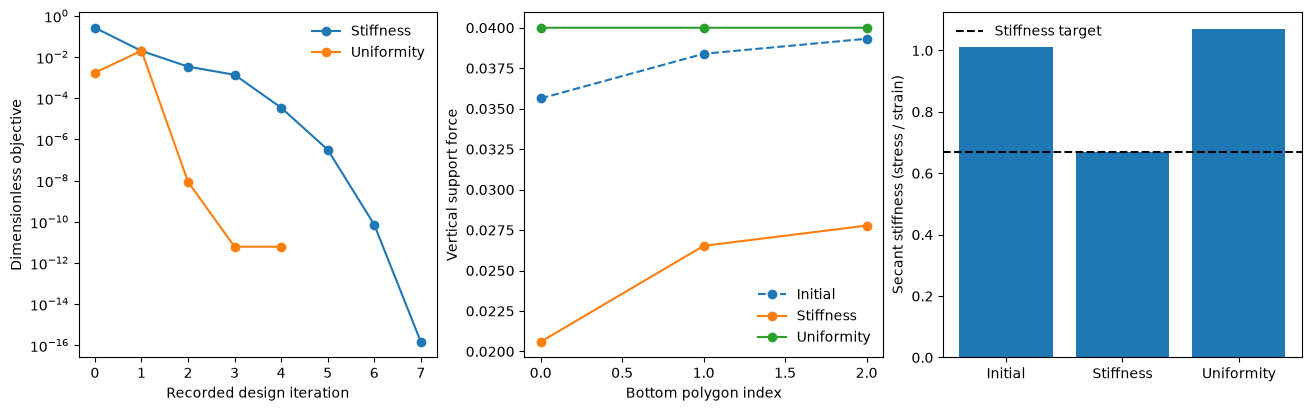

In [7]:
results = {"Stiffness": stiffness_result, "Uniformity": uniformity_result}
print(
    f"{'Design':12s} {'Initial cost':>13s} {'Final cost':>13s} "
    f"{'Stiffness':>12s} {'Total force':>12s} {'Max residual':>13s}"
)
for name, result in results.items():
    solution, stiffness, forces = response(result.parameters)
    solution.check_convergence()
    if float(jnp.sum(forces)) < 0.5 * initial_total_force - 1e-9:
        raise RuntimeError("Final design violates the minimum load")
    print(
        f"{name:12s} {result.initial_loss:13.5g} {result.fun:13.5g} "
        f"{float(stiffness):12.6g} {float(jnp.sum(forces)):12.6g} "
        f"{float(jnp.max(solution.residuals)):13.3g}"
    )
    print(
        "  offsets =",
        np.asarray(result.parameters),
        "; maximum constraint violation =",
        result.max_constraint_violation,
    )

fig, axes = plt.subplots(1, 3, figsize=(13, 4), layout="constrained")
axes[1].plot(np.asarray(bottom), initial_forces, "o--", label="Initial")
stiffness_values = [float(initial_stiffness)]
for name, result in results.items():
    solution, stiffness, forces = response(result.parameters)
    axes[0].semilogy(np.maximum(result.loss_history, 1e-18), "o-", label=name)
    axes[1].plot(np.asarray(bottom), forces, "o-", label=name)
    stiffness_values.append(float(stiffness))
axes[0].set(xlabel="Recorded design iteration", ylabel="Dimensionless objective")
axes[0].legend(frameon=False)
axes[1].set(xlabel="Bottom polygon index", ylabel="Vertical support force")
axes[1].legend(frameon=False)
axes[2].bar(["Initial", *results], stiffness_values)
axes[2].axhline(target_stiffness, color="black", ls="--", label="Stiffness target")
axes[2].set(ylabel="Secant stiffness (stress / strain)")
axes[2].legend(frameon=False)
plt.show()

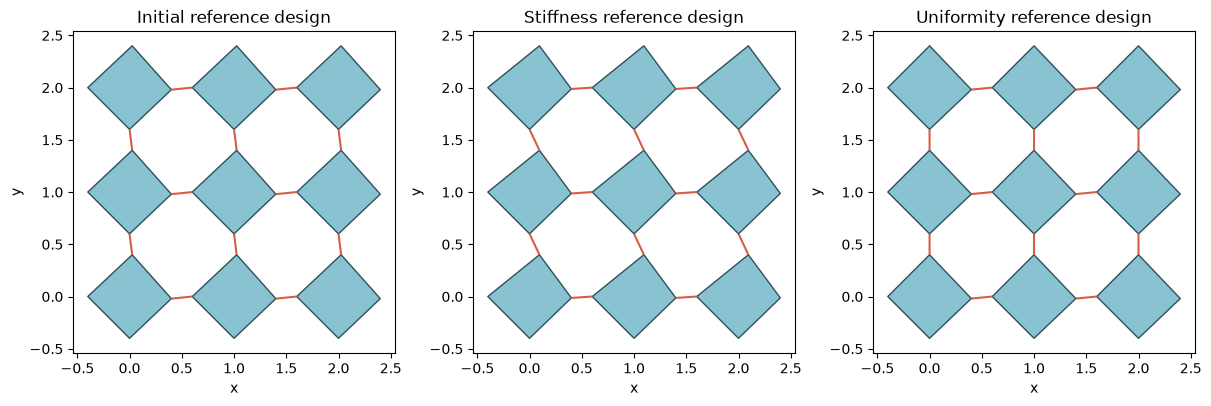

In [8]:
# Inspect the physical shapes as well as numerical costs.
fig, axes = plt.subplots(1, 3, figsize=(12, 4), layout="constrained")
plot_geometry(
    problem.geometry,
    vertices=problem.vertices_from_parameters(problem.initial_parameters),
    ax=axes[0],
)
axes[0].set_title("Initial reference design")
for ax, (name, result) in zip(axes[1:], results.items()):
    plot_geometry(
        problem.geometry, vertices=problem.vertices_from_parameters(result.parameters), ax=ax
    )
    ax.set_title(name + " reference design")
plt.show()

## Change the goal: maximization and weighted combinations

`minimize_design` always minimizes. To **maximize** a quantity, minimize its negative; do not negate a squared target error. For example, `-K_sec / K_scale` maximizes secant stiffness under the same finite offset bounds and geometric restrictions.

For several goals, normalize each cost before choosing weights. The two costs above are already dimensionless, so `w_stiffness * J_stiffness + w_uniformity * J_uniformity` is well-defined. Different weights trade off different designs; they do not turn the result into a unique optimum. The definitions below are extension examples, **not additional completed optimization runs**.

In [9]:
def maximize_stiffness_objective(parameters):
    solution, stiffness, _ = response(parameters)
    # Use a fixed baseline scale. Keep the bounds when seeking a maximum.
    cost = -stiffness / initial_stiffness
    return jnp.where(jnp.all(solution.converged), cost, jnp.inf)


def combined_objective(parameters):
    # These nonnegative weights operate on normalized, dimensionless costs.
    weight_stiffness, weight_uniformity = 0.5, 0.5
    return weight_stiffness * stiffness_objective(
        parameters
    ) + weight_uniformity * uniformity_objective(parameters)


# To run either extension, replace the first argument of minimize_design above.
# Check success, feasibility, equilibrium convergence, and the physical metrics.

## Change the design variables

The objective functions accept whatever parameter array `initialize_design` understands. This example uses two scalars repeated across all polygons. To allow independent vertex offsets, a shape map could instead be:

```python
initial_parameters = jnp.zeros_like(geometry.vertices)  # (n_vertices, 2)

def vertices_from_parameters(offsets):
    return geometry.vertices + offsets

def initialize_design(offsets):
    return initialize(geometry, vertices_from_parameters(offsets))
```

Then rebuild the response closure with that initializer, construct one bound pair per **flattened scalar** (two per vertex), and rebuild `make_shape_constraint` using the new shape map. The returned optimizer result has a flat `x`, while `result.parameters` restores the original array shape or PyTree. More variables increase cost and allow more inadmissible trial geometries; retain the constraints and convergence checks.

For stiffness coefficients as design variables, see the dedicated material-optimization example; changing the number of shape variables does not itself change the constitutive parameters.